In [4]:
import pandas as pd
import pyreadstat
from IPython.display import display


def summarize_selected_variables(path, variables):
        df, metadata = pyreadstat.read_sav(path, usecols=variables)

        missing_variables = [column for column in variables if column not in df.columns]
        if missing_variables:
                raise ValueError(f"Variables not found in {path}: {missing_variables}")

        summary = pd.DataFrame({
                "variable": df.columns,
                "label": [metadata.column_names_to_labels.get(column, "") for column in df.columns],
                "dtype": [str(df[column].dtype) for column in df.columns],
                "non_missing": [int(df[column].notna().sum()) for column in df.columns],
                "missing": [int(df[column].isna().sum()) for column in df.columns],
                "n_unique": [int(df[column].nunique(dropna=True)) for column in df.columns],
                "mean": [pd.to_numeric(df[column], errors="coerce").mean() for column in df.columns],
                "std": [pd.to_numeric(df[column], errors="coerce").std() for column in df.columns],
                "min": [pd.to_numeric(df[column], errors="coerce").min() for column in df.columns],
                "median": [pd.to_numeric(df[column], errors="coerce").median() for column in df.columns],
                "max": [pd.to_numeric(df[column], errors="coerce").max() for column in df.columns],
        })

        summary["missing_pct"] = (summary["missing"] / len(df) * 100).round(2)
        return df, metadata, summary


selected_variables = ["B24_B25_Net_earnings", "P_Weights"]
df, metadata, summary = summarize_selected_variables("stats.sav", selected_variables)
print(f"stats.sav: {len(df)} rows, {len(df.columns)} selected variables")
display(summary)

stats.sav: 58170 rows, 2 selected variables


,variable,label,dtype,non_missing,missing,n_unique,mean,std,min,median,max,missing_pct
0,B24_B25_Net_earnings,შრომის ანაზღაურება (საშემოსავლო გადასახადის გა...,float64,13823,44347,12,8.182305,2.361710,1.000000,9.000000,12.000000,76.24
1,P_Weights,შინამეურნეობის წევრის პერსონალური წონა,float64,58170,0,21222,203.749965,158.838129,12.495379,158.940352,3342.857963,0.00


Rows after dropping missing values: 13823


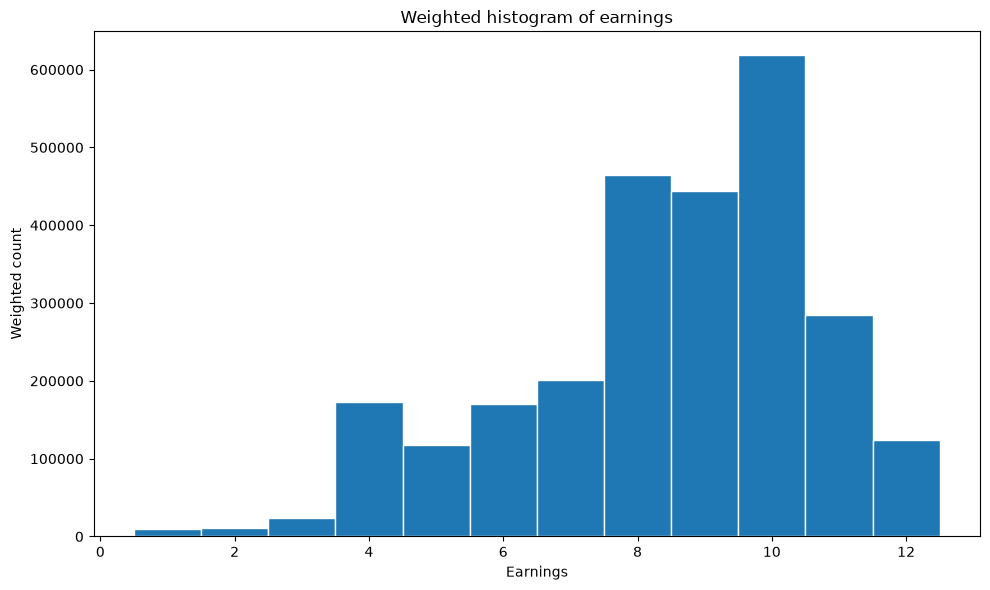

In [5]:
import numpy as np
import matplotlib.pyplot as plt


weighted_df = df[["B24_B25_Net_earnings", "P_Weights"]].copy()
weighted_df = weighted_df.rename(columns={
        "B24_B25_Net_earnings": "earnings",
        "P_Weights": "weights",
})
weighted_df = weighted_df.dropna().reset_index(drop=True)

print(f"Rows after dropping missing values: {len(weighted_df)}")

bins = np.arange(weighted_df["earnings"].min() - 0.5, weighted_df["earnings"].max() + 1.5, 1)

plt.figure(figsize=(10, 6))
plt.hist(
        weighted_df["earnings"],
        bins=bins,
        weights=weighted_df["weights"],
        edgecolor="white",
)
plt.xlabel("Earnings")
plt.ylabel("Weighted count")
plt.title("Weighted histogram of earnings")
plt.tight_layout()
plt.show()

In [6]:
category_stats = (
    weighted_df.groupby("earnings", as_index=False)
    .agg(
        weighted_count=("weights", "sum"),
        unweighted_count=("earnings", "size"),
    )
    .sort_values("earnings")
    .reset_index(drop=True)
)

# Normalize by the weighted total so shares reflect the weighted population.
total_weight = category_stats["weighted_count"].sum()
category_stats["share_of_observations"] = category_stats["weighted_count"] / total_weight
category_stats["cumulative_share"] = category_stats["share_of_observations"].cumsum()

weighted_mean = np.average(weighted_df["earnings"], weights=weighted_df["weights"])
sorted_df = weighted_df.sort_values("earnings").reset_index(drop=True)
cum_weights = sorted_df["weights"].cumsum()
weighted_median = sorted_df.loc[cum_weights >= cum_weights.iloc[-1] / 2, "earnings"].iloc[0]

print(f"Weighted mean earnings: {weighted_mean:.4f}")
print(f"Weighted median earnings: {weighted_median:.4f}")
print(f"Minimum earnings: {weighted_df['earnings'].min():.0f}")
print(f"Maximum earnings: {weighted_df['earnings'].max():.0f}")

display(category_stats[["earnings", "weighted_count", "share_of_observations", "cumulative_share"]])

Weighted mean earnings: 8.4557
Weighted median earnings: 9.0000
Minimum earnings: 1
Maximum earnings: 12


,earnings,weighted_count,share_of_observations,cumulative_share
0,1.0,9007.170351,0.003412,0.003412
1,2.0,10377.177848,0.003931,0.007344
2,3.0,23370.519074,0.008854,0.016198
3,4.0,172213.098024,0.065243,0.081440
4,5.0,117551.458354,0.044534,0.125974
5,6.0,170743.999202,0.064686,0.190660
6,7.0,201255.889717,0.076245,0.266906
7,8.0,464001.885829,0.175786,0.442692
8,9.0,444643.328587,0.168452,0.611144
9,10.0,618310.196370,0.234245,0.845389
